# Sección 1: Importación de Librerías y Carga de Datos

En esta sección se importan las dependencias del proyecto, se carga el conjunto de datos con codificación `utf-8-sig`, se revisan las dimensiones y primeros registros, y se valida la presencia íntegra de las columnas del diccionario.

In [1]:
# Importación de librerías principales
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn
import imblearn
from IPython.display import display

# Configuración básica de visualización
plt.style.use("seaborn-v0_8-whitegrid" if "seaborn-v0_8-whitegrid" in plt.style.available else "default")
print(f"Pandas versión: {pd.__version__}")

Pandas versión: 3.0.6


In [2]:
# Carga del archivo CSV con codificación utf-8-sig
df = pd.read_csv("transacciones_bancarias_fraude.csv", encoding="utf-8-sig")

# Dimensiones del dataset
print(f"Dimensiones (filas, columnas): {df.shape}")

# Primeras 5 filas del dataset
df.head()

Dimensiones (filas, columnas): (30090, 13)


,id_transaccion,monto,hora_transaccion,distancia_ubicacion,frecuencia_transacciones,monto_promedio_cliente,dispositivo_nuevo,ubicacion_nueva,tipo_transaccion,canal,metodo_autenticacion,antiguedad_cliente_meses,fraude
0,TX010403,505.68,16,11.38,2,420.04,1,0,Pago,POS,Tarjeta,34,0
1,TX003473,97.93,17,6.50,4,58.77,0,0,Pago,Aplicación móvil,Clave,77,0
2,TX001435,38.36,16,15.65,2,55.39,0,0,Compra,POS,Tarjeta,76,0
3,TX007058,52.36,16,16.33,4,137.29,0,0,Retiro,Web,Biometría,31,0
4,TX011553,60.84,16,14.09,3,70.20,0,0,Compra,Aplicación móvil,Biometría,76,0


In [3]:
# Información general del DataFrame (tipos de datos y no nulos)
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 30090 entries, 0 to 30089
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   id_transaccion            30090 non-null  str    
 1   monto                     30090 non-null  float64
 2   hora_transaccion          30090 non-null  int64  
 3   distancia_ubicacion       29785 non-null  float64
 4   frecuencia_transacciones  30090 non-null  int64  
 5   monto_promedio_cliente    29604 non-null  float64
 6   dispositivo_nuevo         30090 non-null  int64  
 7   ubicacion_nueva           30090 non-null  int64  
 8   tipo_transaccion          30090 non-null  str    
 9   canal                     30090 non-null  str    
 10  metodo_autenticacion      29843 non-null  str    
 11  antiguedad_cliente_meses  30090 non-null  int64  
 12  fraude                    30090 non-null  int64  
dtypes: float64(3), int64(6), str(4)
memory usage: 3.0 MB


In [4]:
# Verificación de columnas del diccionario de datos
columnas_esperadas = [
    "id_transaccion", "monto", "hora_transaccion", "distancia_ubicacion",
    "frecuencia_transacciones", "monto_promedio_cliente", "dispositivo_nuevo",
    "ubicacion_nueva", "tipo_transaccion", "canal", "metodo_autenticacion",
    "antiguedad_cliente_meses", "fraude"
]

columnas_actuales = df.columns.tolist()
columnas_faltantes = [col for col in columnas_esperadas if col not in columnas_actuales]
columnas_extra = [col for col in columnas_actuales if col not in columnas_esperadas]

print(f"Columnas esperadas: {len(columnas_esperadas)} | Columnas detectadas: {len(columnas_actuales)}")
if not columnas_faltantes and not columnas_extra:
    print("✓ Verificación exitosa: Todas las columnas del diccionario están presentes.")
else:
    if columnas_faltantes:
        print(f"✗ Columnas faltantes: {columnas_faltantes}")
    if columnas_extra:
        print(f"✗ Columnas no esperadas: {columnas_extra}")

Columnas esperadas: 13 | Columnas detectadas: 13
✓ Verificación exitosa: Todas las columnas del diccionario están presentes.


# Sección 2: Análisis Exploratorio de Datos (EDA)

Exploración de la calidad de los datos, distribución de variables categóricas y numéricas, balance de la variable objetivo y detección de valores atípicos.

### 2.a Valores faltantes: conteo y porcentaje por columna

In [5]:
# Conteo y porcentaje de valores faltantes por columna
nulos = df.isnull().sum()
pct_nulos = (df.isnull().mean() * 100).round(2)
tabla_nulos = pd.DataFrame({"Faltantes": nulos, "Porcentaje (%)": pct_nulos})
display(tabla_nulos[tabla_nulos["Faltantes"] > 0])

,Faltantes,Porcentaje (%)
distancia_ubicacion,305,1.01
monto_promedio_cliente,486,1.62
metodo_autenticacion,247,0.82


**Interpretación:** Solo 3 variables presentan valores faltantes: `monto_promedio_cliente` (486 registros, 1,62 %), `distancia_ubicacion` (305, 1,01 %) y `metodo_autenticacion` (247, 0,82 %). Todos están por debajo del 2 %, por lo que no conviene eliminar filas: se imputarán (mediana en las numéricas por su asimetría y moda en la categórica). La imputación se ajustará solo con el conjunto de entrenamiento, dentro del pipeline, para evitar fuga de información.

### 2.b Duplicados exactos

In [6]:
# Conteo de registros duplicados exactos
num_duplicados = df.duplicated().sum()
print(f"Total de duplicados exactos: {num_duplicados}")

Total de duplicados exactos: 90


**Interpretación:** Se detectaron 90 registros duplicados exactos (≈0,30 %). Se eliminarán antes de dividir en entrenamiento y prueba; de lo contrario, una misma transacción podría caer en ambos conjuntos y las métricas saldrían infladas (data leakage).

### 2.c Distribución de variables categóricas

,Conteo,Porcentaje (%)
tipo_transaccion,,
Compra,14780,49.12
Pago,7120,23.66
Transferencia,4878,16.21
Retiro,3312,11.01


,Conteo,Porcentaje (%)
canal,,
Aplicación móvil,10433,34.67
POS,10266,34.12
Web,6925,23.01
Cajero,2466,8.20


,Conteo,Porcentaje (%)
metodo_autenticacion,,
Tarjeta,15424,51.26
Clave,5918,19.67
Biometría,5686,18.90
Token,2815,9.36
NaN,247,0.82


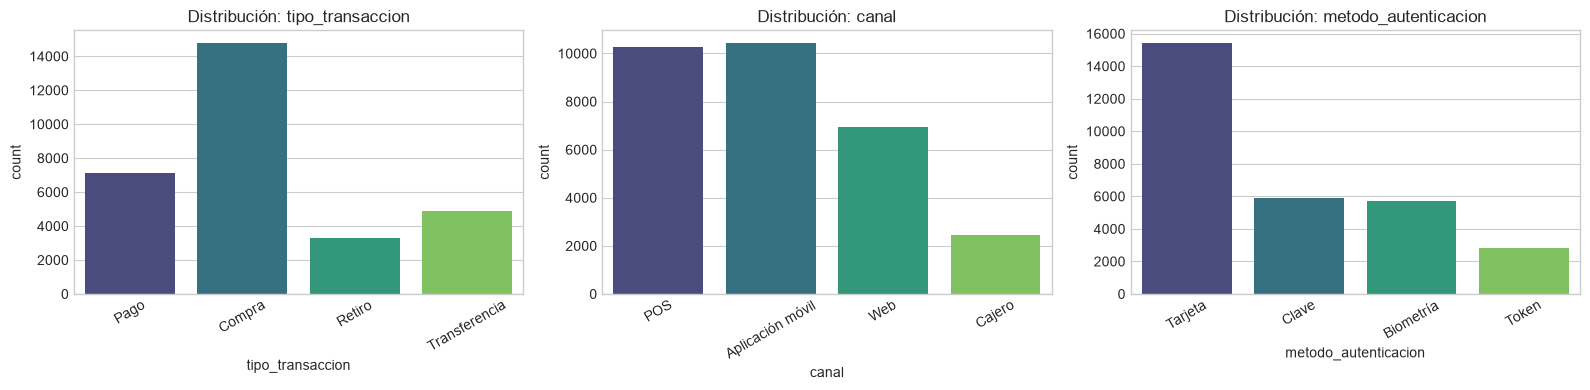

In [7]:
# Distribución de variables categóricas con conteos, porcentajes y countplots
cat_cols = ["tipo_transaccion", "canal", "metodo_autenticacion"]

for col in cat_cols:
    conteo = df[col].value_counts(dropna=False)
    pct = (df[col].value_counts(normalize=True, dropna=False) * 100).round(2)
    display(pd.DataFrame({"Conteo": conteo, "Porcentaje (%)": pct}))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for i, col in enumerate(cat_cols):
    sns.countplot(data=df, x=col, hue=col, ax=axes[i], palette="viridis", legend=False)
    axes[i].set_title(f"Distribución: {col}")
    axes[i].tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

**Interpretación:** `tipo_transaccion` está dominada por Compra (49,12 %), seguida de Pago (23,66 %), Transferencia (16,21 %) y Retiro (11,01 %). En `canal` predominan Aplicación móvil (34,67 %) y POS (34,12 %), con Web (23,01 %) y Cajero (8,20 %) menos frecuentes. En `metodo_autenticacion` domina Tarjeta (51,26 %); el resto se reparte entre Clave, Biometría y Token (9,36 %), y hay 0,82 % de nulos. Todas tienen pocas categorías y ninguna con frecuencia insignificante, por lo que One-Hot Encoding es adecuado y no genera demasiadas columnas.

### 2.d Variables numéricas: estadísticas descriptivas e histogramas

,monto,hora_transaccion,distancia_ubicacion,frecuencia_transacciones,monto_promedio_cliente,dispositivo_nuevo,ubicacion_nueva,antiguedad_cliente_meses,fraude
count,30090.00,30090.00,29785.00,30090.00,29604.00,30090.00,30090.00,30090.00,30090.00
mean,106.72,13.62,11.79,2.20,80.37,0.09,0.09,53.83,0.03
std,147.87,4.79,21.02,1.71,53.74,0.28,0.28,34.82,0.16
min,2.58,0.00,0.00,0.00,7.03,0.00,0.00,1.00,0.00
25%,39.74,11.00,2.76,1.00,44.87,0.00,0.00,28.00,0.00
50%,69.56,14.00,6.69,2.00,67.07,0.00,0.00,47.00,0.00
75%,123.48,17.00,13.60,3.00,100.59,0.00,0.00,72.00,0.00
max,5000.00,23.00,500.00,15.00,1269.98,1.00,1.00,240.00,1.00


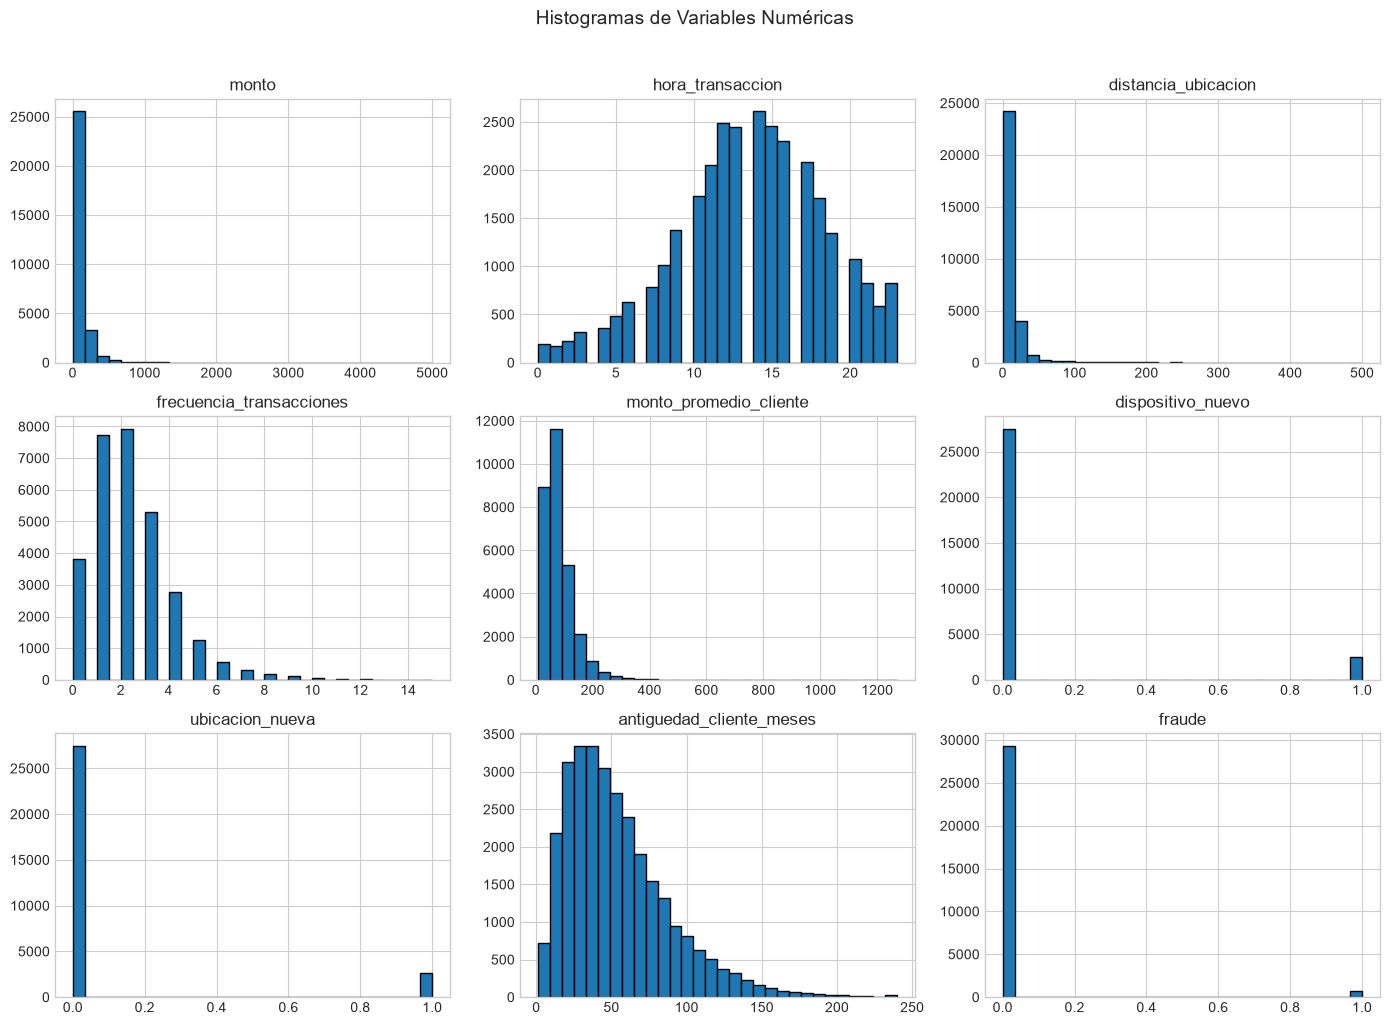

In [8]:
# Estadísticas descriptivas de variables numéricas
display(df.describe().round(2))

# Histogramas de distribución para variables numéricas
num_cols = df.select_dtypes(include=[np.number]).columns
df[num_cols].hist(figsize=(14, 10), bins=30, edgecolor="black", grid=True)
plt.suptitle("Histogramas de Variables Numéricas", fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

**Interpretación:** `monto`, `distancia_ubicacion`, `monto_promedio_cliente` y `antiguedad_cliente_meses` presentan asimetría positiva: la media supera a la mediana (por ejemplo, monto 106,72 vs 69,56; distancia 11,79 vs 6,69) y existen valores muy altos (monto máximo 5.000, distancia máxima 500 km). `hora_transaccion` se concentra entre las 11 y las 18 h (mediana 14), con poca actividad en la madrugada. `frecuencia_transacciones` tiene mediana 2 y máximo 15. `dispositivo_nuevo` y `ubicacion_nueva` son binarias y valen 1 en cerca del 9 % de los casos. Como las escalas son muy distintas (monto hasta 5.000 frente a variables 0/1), se aplicará estandarización, necesaria para Regresión Logística, KNN, SVM y MLP.

### 2.e Proporción de fraude vs legítimas

,Conteo,Porcentaje (%)
fraude,,
0,29321,97.44
1,769,2.56


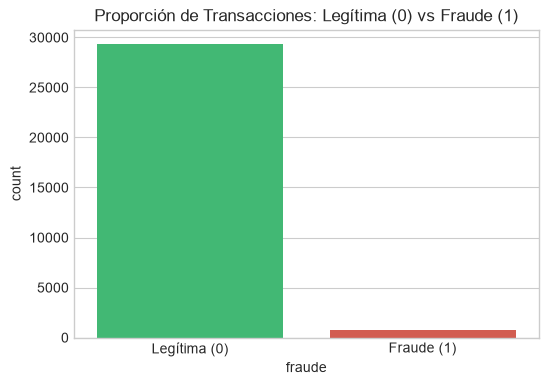

In [9]:
# Conteo y porcentaje de la variable objetivo (fraude)
conteo_fraude = df["fraude"].value_counts()
pct_fraude = (df["fraude"].value_counts(normalize=True) * 100).round(2)
display(pd.DataFrame({"Conteo": conteo_fraude, "Porcentaje (%)": pct_fraude}))

# Gráfico de barras de la variable objetivo
plt.figure(figsize=(6, 4))
ax = sns.countplot(data=df, x="fraude", hue="fraude", palette=["#2ecc71", "#e74c3c"], legend=False)
ax.set_title("Proporción de Transacciones: Legítima (0) vs Fraude (1)")
ax.set_xticks([0, 1], labels=["Legítima (0)", "Fraude (1)"])
plt.show()

**Interpretación:** Hay 29.321 transacciones legítimas (97,44 %) y 769 fraudulentas (2,56 %): una relación aproximada de 38 a 1, lo que confirma un problema de clases desbalanceadas. Un modelo que clasificara todo como legítimo tendría un 97,44 % de Accuracy sin detectar ningún fraude (Recall = 0), por eso el análisis se basará en Recall, Precision, F1 y AUC-ROC, usando división y validación cruzada estratificadas y un tratamiento explícito del desbalance.

### 2.f Detección de valores atípicos (regla IQR y boxplots)

,Q1,Q3,IQR,Límite Inf,Límite Sup,Atípicos,Porcentaje (%)
Variable,,,,,,,
monto,39.74,123.48,83.73,-85.86,249.08,2236,7.43
distancia_ubicacion,2.76,13.60,10.84,-13.50,29.86,1907,6.40
frecuencia_transacciones,1.00,3.00,2.00,-2.00,6.00,732,2.43


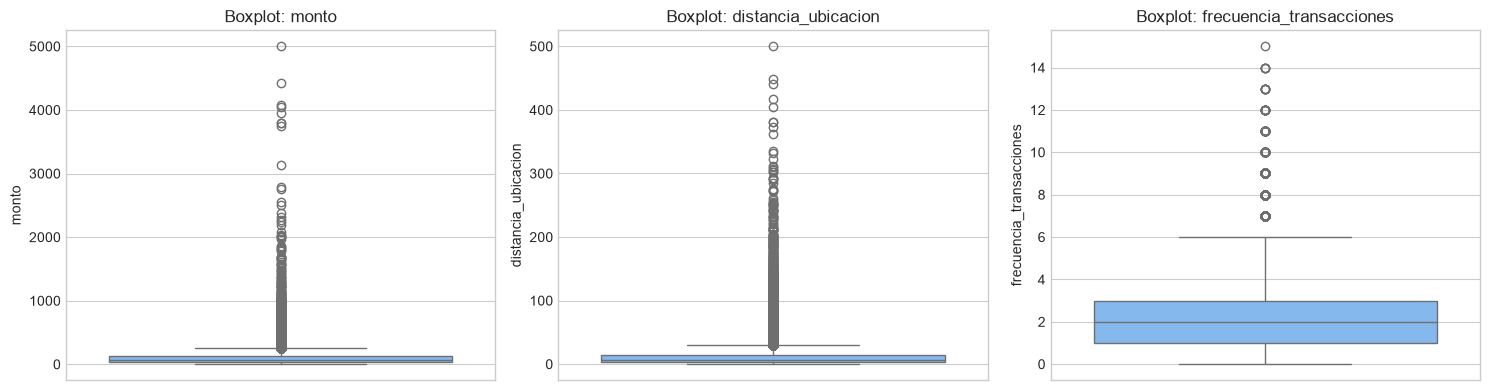

In [10]:
# Detección de valores atípicos por regla IQR
cols_atipicos = ["monto", "distancia_ubicacion", "frecuencia_transacciones"]
iqr_summary = []
for col in cols_atipicos:
    s = df[col].dropna()
    q1 = s.quantile(0.25)
    q3 = s.quantile(0.75)
    iqr = q3 - q1
    lim_inf = q1 - 1.5 * iqr
    lim_sup = q3 + 1.5 * iqr
    outliers = ((s < lim_inf) | (s > lim_sup)).sum()
    pct = (outliers / len(s)) * 100
    iqr_summary.append({
        "Variable": col, "Q1": round(q1, 2), "Q3": round(q3, 2), "IQR": round(iqr, 2),
        "Límite Inf": round(lim_inf, 2), "Límite Sup": round(lim_sup, 2),
        "Atípicos": outliers, "Porcentaje (%)": round(pct, 2)
    })
display(pd.DataFrame(iqr_summary).set_index("Variable"))

# Boxplots para visualización de atípicos
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for i, col in enumerate(cols_atipicos):
    sns.boxplot(y=df[col], ax=axes[i], color="#74b9ff")
    axes[i].set_title(f"Boxplot: {col}")
plt.tight_layout()
plt.show()

**Interpretación:** Por la regla del IQR hay 2.236 atípicos en `monto` (7,43 %, límite superior 249,08), 1.907 en `distancia_ubicacion` (6,40 %, límite 29,86) y 732 en `frecuencia_transacciones` (2,43 %, límite 6). No se eliminarán: montos altos, distancias grandes y ráfagas de transacciones son comportamientos típicos de fraude, así que contienen información que el modelo debe aprender. Como los atípicos (7,43 % en monto) superan la tasa de fraude (2,56 %), no todos son fraudes: también hay clientes legítimos con compras grandes o lejanas.

## Sección 2.1: Análisis Bivariado respecto a Fraude

Evaluación de la relación de cada variable explicativa con respecto a la variable objetivo `fraude`.

### 2.1.a Tasa de fraude (%) por variables categóricas y binarias

In [11]:
# Tasa de fraude (%) por categorías y variables binarias
vars_cat = ["tipo_transaccion", "canal", "metodo_autenticacion", "dispositivo_nuevo", "ubicacion_nueva"]

for var in vars_cat:
    tabla = df.groupby(var, dropna=False)["fraude"].agg(
        Total="count",
        Casos_Fraude="sum",
        Tasa_Fraude_Pct=lambda x: (x.mean() * 100).round(2)
    )
    display(tabla)

,Total,Casos_Fraude,Tasa_Fraude_Pct
tipo_transaccion,,,
Compra,14780,270,1.83
Pago,7120,52,0.73
Retiro,3312,174,5.25
Transferencia,4878,273,5.60


,Total,Casos_Fraude,Tasa_Fraude_Pct
canal,,,
Aplicación móvil,10433,252,2.42
Cajero,2466,99,4.01
POS,10266,109,1.06
Web,6925,309,4.46


,Total,Casos_Fraude,Tasa_Fraude_Pct
metodo_autenticacion,,,
Biometría,5686,60,1.06
Clave,5918,272,4.60
Tarjeta,15424,358,2.32
Token,2815,72,2.56
NaN,247,7,2.83


,Total,Casos_Fraude,Tasa_Fraude_Pct
dispositivo_nuevo,,,
0,27532,418,1.52
1,2558,351,13.72


,Total,Casos_Fraude,Tasa_Fraude_Pct
ubicacion_nueva,,,
0,27470,307,1.12
1,2620,462,17.63


### 2.1.b Boxplots por condición de fraude (escala logarítmica en monto y distancia)

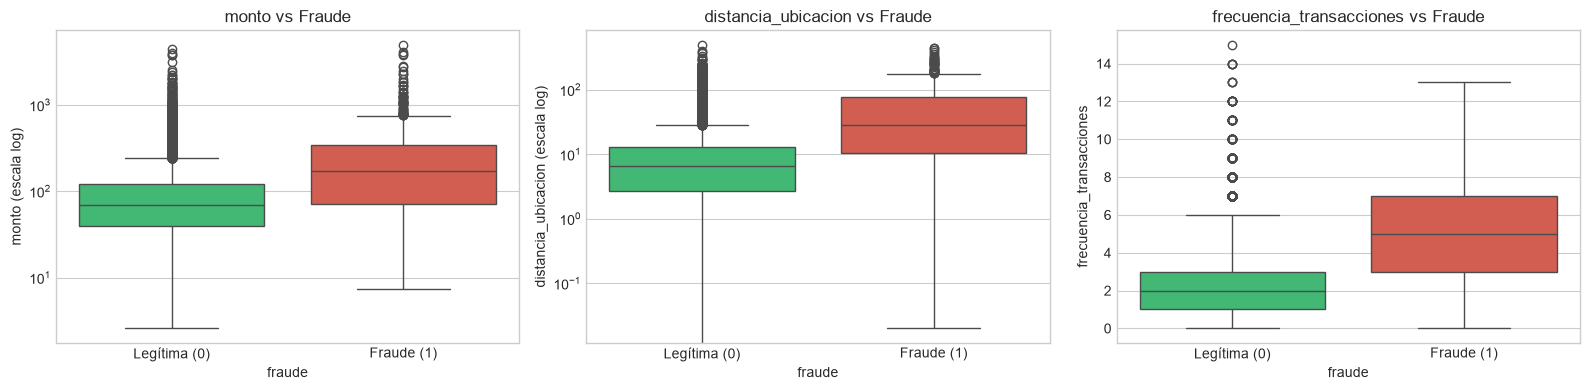

In [12]:
# Boxplots comparativos respecto a fraude (0 vs 1) con escala log en monto y distancia
cols_biv = ["monto", "distancia_ubicacion", "frecuencia_transacciones"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))

for i, col in enumerate(cols_biv):
    sns.boxplot(data=df, x="fraude", y=col, hue="fraude", ax=axes[i], palette=["#2ecc71", "#e74c3c"], legend=False)
    axes[i].set_title(f"{col} vs Fraude")
    axes[i].set_xticks([0, 1], labels=["Legítima (0)", "Fraude (1)"])
    if col in ["monto", "distancia_ubicacion"]:
        axes[i].set_yscale("log")
        axes[i].set_ylabel(f"{col} (escala log)")

plt.tight_layout()
plt.show()

### 2.1.c Tasa de fraude por hora de la transacción

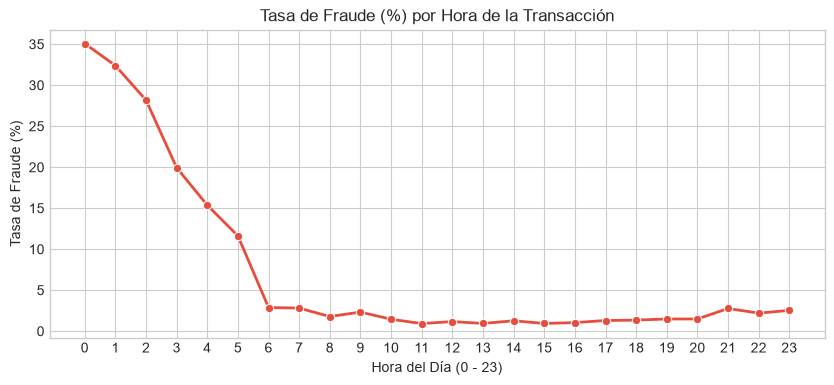

In [13]:
# Gráfico de línea: tasa de fraude (%) por hora de la transacción
tasa_hora = (df.groupby("hora_transaccion")["fraude"].mean() * 100).reset_index()

plt.figure(figsize=(10, 4))
sns.lineplot(data=tasa_hora, x="hora_transaccion", y="fraude", marker="o", color="#e74c3c", linewidth=2)
plt.title("Tasa de Fraude (%) por Hora de la Transacción")
plt.xlabel("Hora del Día (0 - 23)")
plt.ylabel("Tasa de Fraude (%)")
plt.xticks(range(0, 24))
plt.grid(True)
plt.show()

### Interpretación del análisis bivariado (fraude vs. variables)

**Variables binarias.** Son las que más separan el fraude. Con `ubicacion_nueva` = 1 la tasa de fraude es 17,63 % (462 de 2.620 casos) frente a 1,12 % cuando es 0. Con `dispositivo_nuevo` = 1 es 13,72 % (351 de 2.558) frente a 1,52 %. Ambas multiplican entre 5 y 7 veces la tasa global (2,56 %) y concentran la mayoría de los fraudes (462 y 351 de 769).

**Variables categóricas.** El fraude es más frecuente en Transferencia (5,60 %) y Retiro (5,25 %) que en Compra (1,83 %) y Pago (0,73 %). Por canal, Web (4,46 %) y Cajero (4,01 %) superan a Aplicación móvil (2,42 %) y POS (1,06 %). Por método de autenticación, Clave (4,60 %) es el más riesgoso y Biometría (1,06 %) el más seguro. Los nulos de `metodo_autenticacion` (2,83 %) se comportan parecido a la tasa global, por lo que imputarlos no distorsiona el análisis.

**Variables numéricas.** Las transacciones fraudulentas tienen una mediana mayor en `monto` (aprox. 170 vs 70 USD), `distancia_ubicacion` (aprox. 28 vs 7 km) y `frecuencia_transacciones` (5 vs 2 en 24 h). Aun así, las cajas se solapan, así que ninguna variable separa las clases por sí sola: se necesita un modelo que las combine.

**Hora del día.** La tasa de fraude es muy alta en la madrugada (aprox. 35 % a las 0 h y baja hasta cerca de 12 % a las 5 h) y se estabiliza entre 1 % y 3 % desde las 6 h. La hora aporta información, pero su relación no es lineal.

**Conclusión.** Los fraudes se asocian con ubicación y dispositivo nuevos, transferencias y retiros, canales Web y Cajero, madrugada, mayor monto, mayor distancia y más transacciones en 24 h. Esto respalda usar modelos capaces de capturar combinaciones de variables, como Random Forest, además de la Regresión Logística como línea base.

# Sección 3: Preparación de Datos y Preprocesamiento

En esta sección se limpian los registros duplicados, se exporta el dataset depurado, se dividen los datos en conjuntos de entrenamiento y prueba mediante estratificación, y se define el transformador de columnas (`ColumnTransformer`) sin ajustarlo, evitando cualquier tipo de fuga de información (*data leakage*).

### 3.1 Limpieza de duplicados y exportación del dataset

In [14]:
# (1) Eliminación de duplicados exactos
df = df.drop_duplicates()
print(f"Filas restantes tras eliminar duplicados: {df.shape[0]}")

# (2) Guardar dataset procesado
df.to_csv("dataset_procesado.csv", encoding="utf-8-sig", index=False)
print("Dataset procesado guardado exitosamente en 'dataset_procesado.csv'.")

Filas restantes tras eliminar duplicados: 30000
Dataset procesado guardado exitosamente en 'dataset_procesado.csv'.


### 3.2 Separación de variables y partición Train / Test (Estratificada)

In [15]:
from sklearn.model_selection import train_test_split

# (3) Separar predictoras (X) y objetivo (y), excluyendo 'id_transaccion'
X = df.drop(columns=["id_transaccion", "fraude"])
y = df["fraude"]

# (4) División estratificada 80/20 con random_state=42
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

# Tamaños de los conjuntos
print(f"Tamaño X_train: {X_train.shape} | y_train: {y_train.shape}")
print(f"Tamaño X_test:  {X_test.shape}  | y_test:  {y_test.shape}")

# Proporción de fraude en train y test
prop_train = (y_train.value_counts(normalize=True) * 100).round(2)
prop_test = (y_test.value_counts(normalize=True) * 100).round(2)
print("\nProporción de fraude en Train (%):")
print(prop_train.to_string())
print("\nProporción de fraude en Test (%):")
print(prop_test.to_string())

Tamaño X_train: (24000, 11) | y_train: (24000,)
Tamaño X_test:  (6000, 11)  | y_test:  (6000,)

Proporción de fraude en Train (%):
fraude
0    97.45
1     2.55

Proporción de fraude en Test (%):
fraude
0    97.45
1     2.55


### 3.3 Definición del ColumnTransformer (Sin ajuste previo)

> **Prevención de Data Leakage:** El `ColumnTransformer` se define **sin ajustarlo** (`fit` o `fit_transform`). El cálculo de estadísticas (medianas para imputación, medias y varianzas para estandarización, y categorías para one-hot encoding) se realizará estrictamente sobre los datos de entrenamiento (`X_train`) dentro de los pipelines de modelado.

In [16]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

# (5) Definición de listas de columnas según su naturaleza
num_cols = [
    "monto", "hora_transaccion", "distancia_ubicacion",
    "frecuencia_transacciones", "monto_promedio_cliente", "antiguedad_cliente_meses"
]
cat_cols = ["tipo_transaccion", "canal", "metodo_autenticacion"]
bin_cols = ["dispositivo_nuevo", "ubicacion_nueva"]

# Pipeline para variables numéricas (mediana + estandarización)
num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

# Pipeline para variables categóricas (moda + OneHotEncoding)
cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

# Ensamblado del preprocesador mediante ColumnTransformer (sin ajustar)
preprocessor = ColumnTransformer(
    transformers=[
        ("num", num_pipeline, num_cols),
        ("cat", cat_pipeline, cat_cols),
        ("bin", "passthrough", bin_cols)
    ],
    remainder="drop"
)

print("ColumnTransformer definido exitosamente (sin ajustar):")
display(preprocessor)

ColumnTransformer definido exitosamente (sin ajustar):


,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the different transformers contains sparse matrices,these will be stacked as a sparse matrix if the overall density islower than this value. Use ``sparse_threshold=0`` to always returndense. When the transformed output consists of all dense data, thestacked result will be dense, and this keyword will be ignored.",0.3
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.",None
,"transformer_weights transformer_weights: dict, default=NoneMultiplicative weights for features per transformer. The output of thetransformer is multiplied by these weights. Keys are transformer names,values the weights.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each transformer will beprinted as it is completed.",False
,"verbose_feature_names_out verbose_feature_names_out: bool, str or Callable[[str, str], str], default=True- If True, :meth:`ColumnTransformer.get_feature_names_out` will prefix all feature names with the name of the transformer that generated that feature. It is equivalent to setting `verbose_feature_names_out=""{transformer_name}__{feature_name}""`.- If False, :meth:`ColumnTransformer.get_feature_names_out` will not prefix any feature names and will error if feature names are not unique.- If ``Callable[[str, str], str]``, :meth:`ColumnTransformer.get_feature_names_out` will rename all the features using the name of the transformer. The first argument of the callable is the transformer name and the second argument is the feature name. The returned string will be the new feature name.- If ``str``, it must be a string ready for formatting. The given string will be formatted using two field names: ``transformer_name`` and ``feature_n

### Interpretación de la preparación de datos

Se eliminaron 90 registros duplicados exactos (0,30 %), quedando 30.000 transacciones. Esto evita que una misma transacción aparezca a la vez en entrenamiento y prueba, lo que inflaría las métricas. Luego se separaron los predictores X (11 variables, sin `id_transaccion`, que es solo un identificador) de la variable objetivo `fraude`.

La división en entrenamiento (24.000) y prueba (6.000) es estratificada 80/20: la proporción de fraude es 2,55 % en ambos conjuntos, así que la prueba representa bien el desbalance real. El conjunto de prueba no se toca hasta la evaluación final.

El preprocesamiento se definió con un ColumnTransformer: las variables numéricas se imputan con la mediana (robusta a valores atípicos) y se estandarizan; las categóricas se imputan con la moda y se codifican con One-Hot; las binarias pasan sin cambios. Todavía no se ajusta: se hará solo con los datos de entrenamiento, dentro de los pipelines, para que nada del conjunto de prueba influya en el modelo (sin data leakage).